# 排序算法性能分析可视化
## Sorting Algorithm Performance Analysis & Visualization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.font_manager as fm
import seaborn as sns
from matplotlib import rcParams

# ========== 注册中文字体 ==========
fm.fontManager.addfont('/home/marrma/.fonts/NotoSansCJKsc-Regular.otf')
fm._load_fontmanager(try_read_cache=False)

# ========== 学术图表全局设置 ==========
rcParams['font.sans-serif'] = ['Noto Sans CJK SC']
rcParams['axes.unicode_minus'] = False
rcParams['font.size'] = 11
rcParams['axes.titlesize'] = 13
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 10
rcParams['ytick.labelsize'] = 10
rcParams['legend.fontsize'] = 9
rcParams['figure.dpi'] = 150
rcParams['savefig.dpi'] = 300
rcParams['savefig.bbox'] = 'tight'
rcParams['axes.linewidth'] = 1.0

print('Libraries imported successfully. CJK font registered.')

Libraries imported successfully. CJK font registered.


In [2]:
# ========== 数据读取与解析 ==========
raw = pd.read_excel('results_release.xlsx', header=None)

# 定义的算法名称和列映射
ALGO_NAMES = ['冒泡排序', '选择排序', '快速排序', '插入排序', '希尔排序', '桶排序']
ALGO_NAMES_EN = ['Bubble', 'Selection', 'Quick', 'Insertion', 'Shell', 'Bucket']

# 各数据段起始行与数据类型标签
# 结构: start_row=段标题行, +1=表头行, +2=第一条数据行(1024)
section_defs = [
    (3,   'i', '完全逆序'),
    (15,  'i', '完全顺序'),
    (27,  'i', '均匀分布'),
    (39,  'i', '正态分布'),
    (51,  'd', '完全逆序'),
    (63,  'd', '完全顺序'),
    (75,  'd', '均匀分布'),
    (87,  'd', '正态分布'),
]

records = []
for start_row, dtype, dist in section_defs:
    for offset in range(9):  # 1024, 2048, ..., 262144
        data_row = start_row + 2 + offset  # +1=表头行, +2=第一条数据行
        N_val = raw.iloc[data_row, 0]
        if pd.isna(N_val):
            break
        N_val = int(N_val)
        for j, algo in enumerate(ALGO_NAMES):
            time_val = raw.iloc[data_row, 1 + j]
            cmp_val  = raw.iloc[data_row, 7 + j]
            asg_val  = raw.iloc[data_row, 13 + j]
            # 跳过-1（表示未完成/溢出）
            if time_val == -1 or cmp_val == -1 or asg_val == -1:
                time_val = np.nan
                cmp_val = np.nan
                asg_val = np.nan
            records.append({
                '数据类型': dtype,
                '数据构型': dist,
                '规模N': N_val,
                '算法': algo,
                '算法英文': ALGO_NAMES_EN[j],
                '执行时间_s': float(time_val) if not pd.isna(time_val) else np.nan,
                '比较次数': float(cmp_val) if not pd.isna(cmp_val) else np.nan,
                '赋值次数': float(asg_val) if not pd.isna(asg_val) else np.nan,
            })

df = pd.DataFrame(records)
print(f'Total records: {len(df)}')
print(f'Columns: {df.columns.tolist()}')
print(f'\nData types: {df["数据类型"].unique()}')
print(f'Distributions: {df["数据构型"].unique()}')
print(f'Algorithms: {df["算法"].unique()}')
print(f'N values: {sorted(df["规模N"].unique())}')
df.head(12)

Total records: 432
Columns: ['数据类型', '数据构型', '规模N', '算法', '算法英文', '执行时间_s', '比较次数', '赋值次数']

Data types: ['i' 'd']
Distributions: ['完全逆序' '完全顺序' '均匀分布' '正态分布']
Algorithms: ['冒泡排序' '选择排序' '快速排序' '插入排序' '希尔排序' '桶排序']
N values: [np.int64(1024), np.int64(2048), np.int64(4096), np.int64(8192), np.int64(16384), np.int64(32768), np.int64(65536), np.int64(131072), np.int64(262144)]


,数据类型,数据构型,规模N,算法,算法英文,执行时间_s,比较次数,赋值次数
0,i,完全逆序,1024,冒泡排序,Bubble,0.002522,523776.0,1571328.0
1,i,完全逆序,1024,选择排序,Selection,0.000897,523776.0,1536.0
2,i,完全逆序,1024,快速排序,Quick,0.000024,9238.0,3585.0
3,i,完全逆序,1024,插入排序,Insertion,0.001290,523776.0,525822.0
4,i,完全逆序,1024,希尔排序,Shell,0.000049,13314.0,23554.0
5,i,完全逆序,1024,桶排序,Bucket,0.000096,3069.0,1024.0
6,i,完全逆序,2048,冒泡排序,Bubble,0.010063,2096128.0,6288384.0
7,i,完全逆序,2048,选择排序,Selection,0.003105,2096128.0,3072.0
8,i,完全逆序,2048,快速排序,Quick,0.000037,20504.0,7169.0
9,i,完全逆序,2048,插入排序,Insertion,0.005235,2096128.0,2100222.0


---
## 第一组：宏观性能总览（趋势分析）
### 图表 1-a：平方级复杂度算法时间曲线 — $O(n^2)$ Algorithms

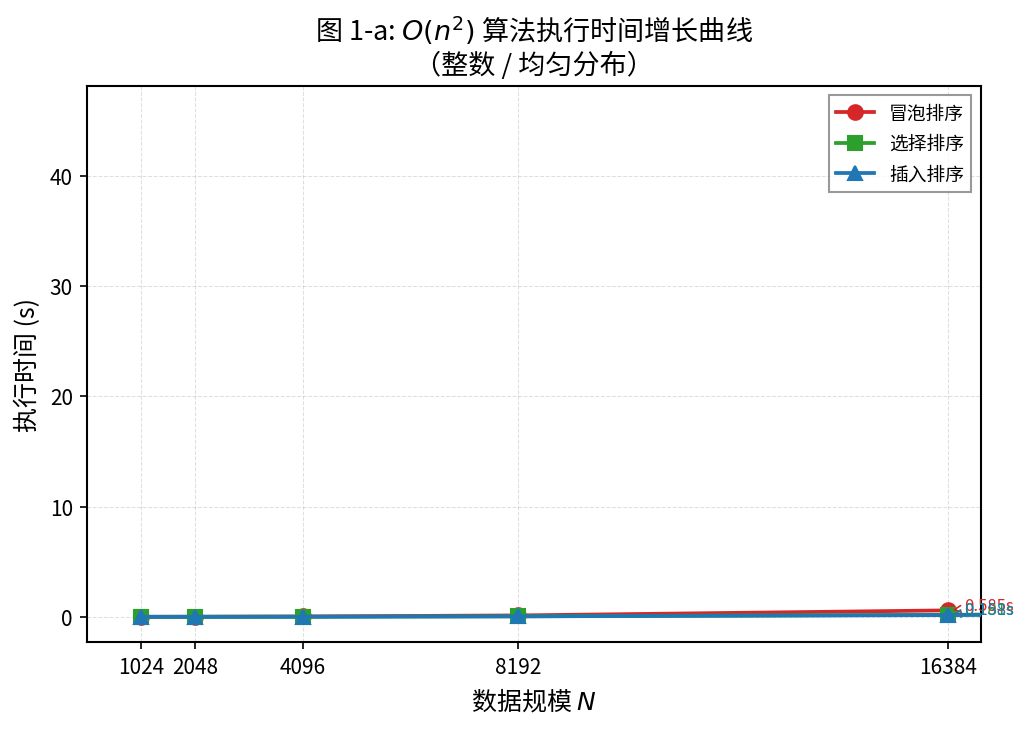

In [3]:
# ========== 图表 1-a: 平方级算法（冒泡、选择、插入）时间曲线 ==========
# 固定条件：整数类型，均匀分布
mask_1a = (df['数据类型'] == 'i') & (df['数据构型'] == '均匀分布') & \
          (df['算法'].isin(['冒泡排序', '选择排序', '插入排序']))
df_1a = df[mask_1a].dropna(subset=['执行时间_s']).copy()

fig, ax = plt.subplots(figsize=(7, 5))

colors_o2 = {'冒泡排序': '#d62728', '选择排序': '#2ca02c', '插入排序': '#1f77b4'}
markers_o2 = {'冒泡排序': 'o', '选择排序': 's', '插入排序': '^'}

for algo in ['冒泡排序', '选择排序', '插入排序']:
    sub = df_1a[df_1a['算法'] == algo].sort_values('规模N')
    ax.plot(sub['规模N'], sub['执行时间_s'],
            color=colors_o2[algo], marker=markers_o2[algo],
            linewidth=1.8, markersize=7, label=algo, zorder=3)

ax.set_xlabel('数据规模 $N$')
ax.set_ylabel('执行时间 (s)')
ax.set_title('图 1-a: $O(n^2)$ 算法执行时间增长曲线\n（整数 / 均匀分布）')
ax.legend(frameon=True, fancybox=False, edgecolor='gray')
ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.5)
ax.set_xscale('linear')
ax.set_xticks(sorted(df_1a['规模N'].unique()))
ax.set_xlim(0, 17000)

# 标注N=16384的具体数值
for algo in ['冒泡排序', '选择排序', '插入排序']:
    sub = df_1a[(df_1a['算法'] == algo) & (df_1a['规模N'] == 16384)]
    if len(sub):
        t = sub['执行时间_s'].values[0]
        ax.annotate(f'{t:.3f}s', xy=(16384, t), xytext=(16384+300, t+0.02),
                    fontsize=8, color=colors_o2[algo],
                    arrowprops=dict(arrowstyle='->', color=colors_o2[algo], lw=0.8))

plt.tight_layout()
plt.savefig('fig1a_o_n2_time_curve.png', dpi=300)
plt.show()

### 图表 1-b：对数/线性级复杂度算法时间曲线 — $O(n \log n)$ / Sub-quadratic Algorithms

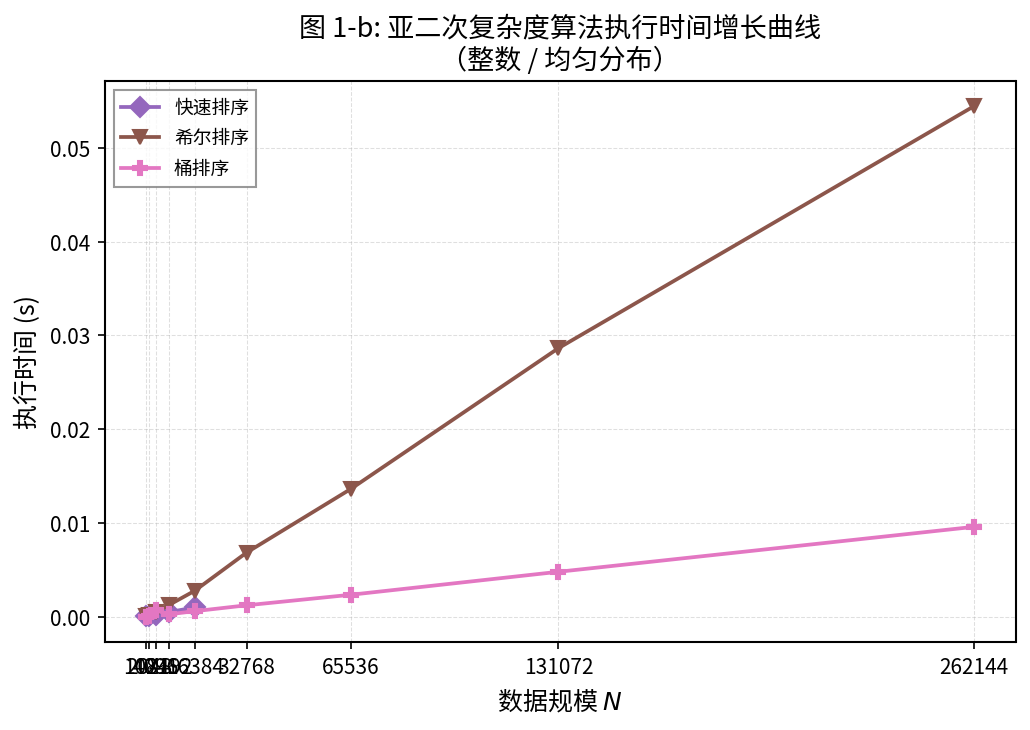

In [4]:
# ========== 图表 1-b: 快速算法（快排、希尔、桶排）时间曲线 ==========
mask_1b = (df['数据类型'] == 'i') & (df['数据构型'] == '均匀分布') & \
          (df['算法'].isin(['快速排序', '希尔排序', '桶排序']))
df_1b = df[mask_1b].dropna(subset=['执行时间_s']).copy()

fig, ax = plt.subplots(figsize=(7, 5))

colors_fast = {'快速排序': '#9467bd', '希尔排序': '#8c564b', '桶排序': '#e377c2'}
markers_fast = {'快速排序': 'D', '希尔排序': 'v', '桶排序': 'P'}

for algo in ['快速排序', '希尔排序', '桶排序']:
    sub = df_1b[df_1b['算法'] == algo].sort_values('规模N')
    ax.plot(sub['规模N'], sub['执行时间_s'],
            color=colors_fast[algo], marker=markers_fast[algo],
            linewidth=1.8, markersize=7, label=algo, zorder=3)

ax.set_xlabel('数据规模 $N$')
ax.set_ylabel('执行时间 (s)')
ax.set_title('图 1-b: 亚二次复杂度算法执行时间增长曲线\n（整数 / 均匀分布）')
ax.legend(frameon=True, fancybox=False, edgecolor='gray')
ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.5)
ax.set_xticks(sorted(df_1b['规模N'].unique()))

plt.tight_layout()
plt.savefig('fig1b_fast_time_curve.png', dpi=300)
plt.show()

---
### 图表 2：比较次数与赋值次数增长图（对数折线图）

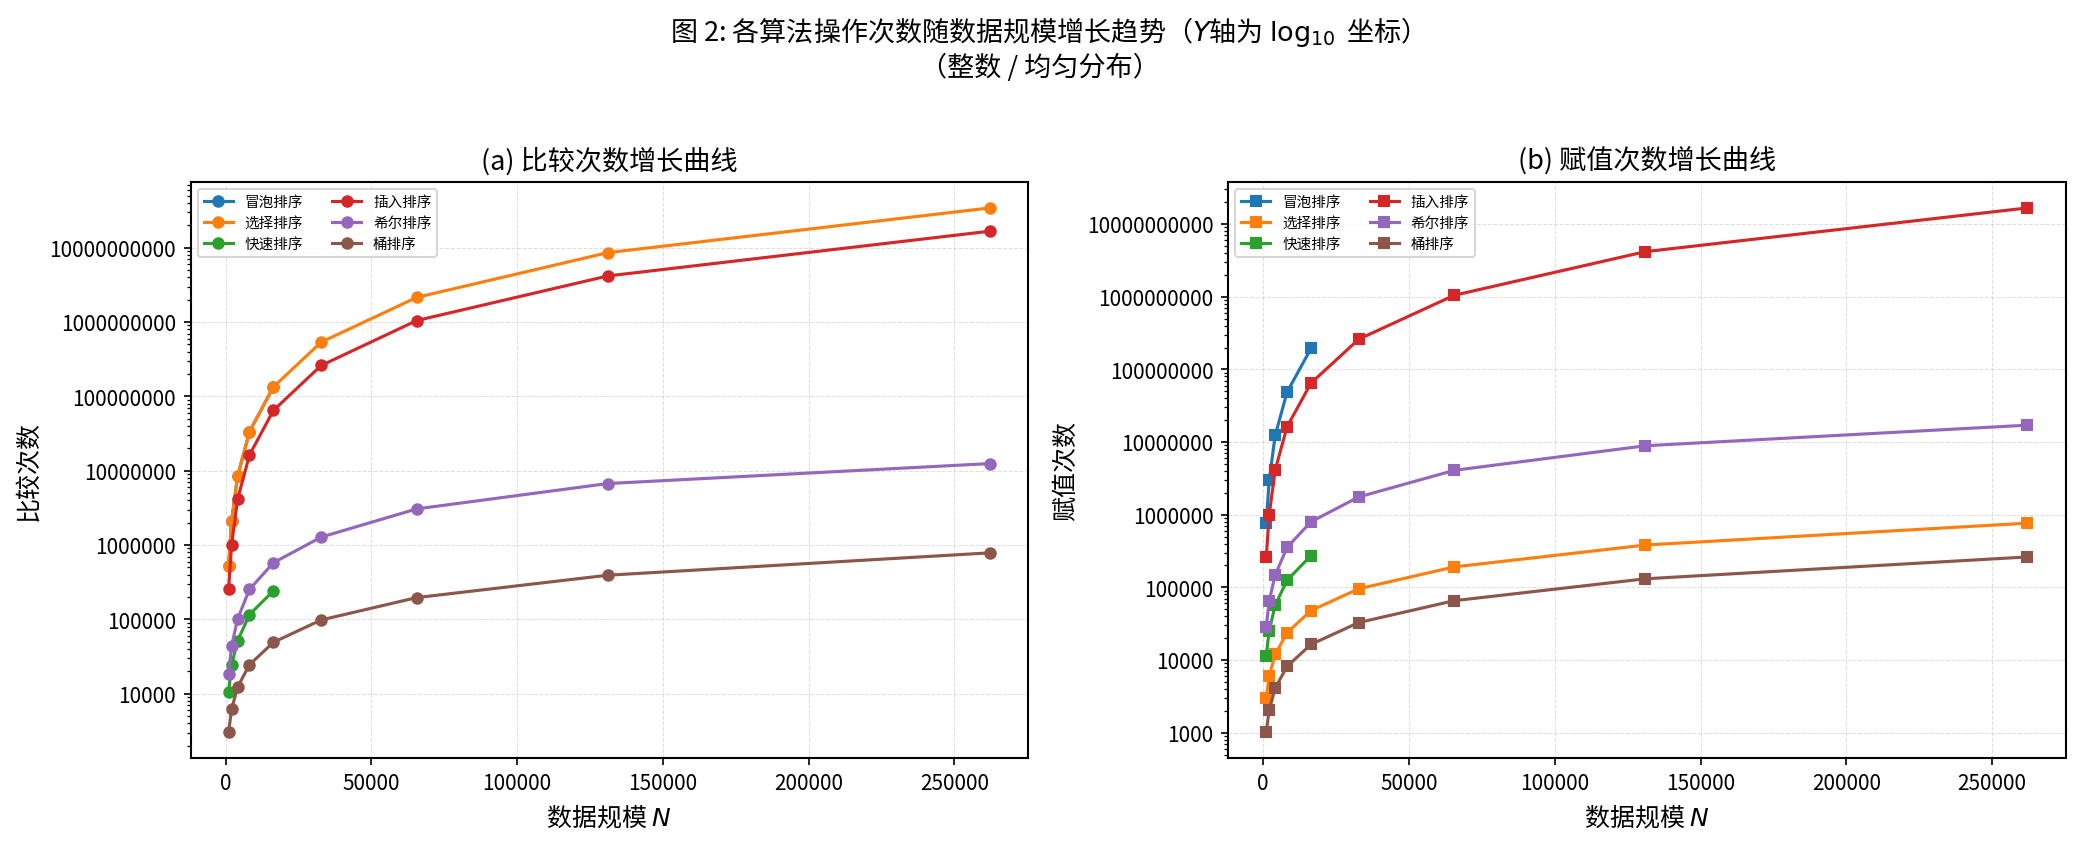

In [5]:
# ========== 图表 2: 操作次数增长图（Y轴 Log10） ==========
# 固定条件：整数类型，均匀分布
mask_2 = (df['数据类型'] == 'i') & (df['数据构型'] == '均匀分布')
df_2 = df[mask_2].dropna(subset=['比较次数', '赋值次数']).copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 图2-a: 比较次数
ax = axes[0]
for algo in ALGO_NAMES:
    sub = df_2[df_2['算法'] == algo].sort_values('规模N')
    ax.plot(sub['规模N'], sub['比较次数'], marker='o', linewidth=1.5, markersize=5, label=algo)
ax.set_xlabel('数据规模 $N$')
ax.set_ylabel('比较次数')
ax.set_title('(a) 比较次数增长曲线')
ax.set_yscale('log', base=10)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=10))
ax.legend(fontsize=7, ncol=2)
ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.5)

# 图2-b: 赋值次数
ax = axes[1]
for algo in ALGO_NAMES:
    sub = df_2[df_2['算法'] == algo].sort_values('规模N')
    ax.plot(sub['规模N'], sub['赋值次数'], marker='s', linewidth=1.5, markersize=5, label=algo)
ax.set_xlabel('数据规模 $N$')
ax.set_ylabel('赋值次数')
ax.set_title('(b) 赋值次数增长曲线')
ax.set_yscale('log', base=10)
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=10))
ax.legend(fontsize=7, ncol=2)
ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.5)

fig.suptitle('图 2: 各算法操作次数随数据规模增长趋势（$Y$轴为 $\\log_{10}$ 坐标）\n（整数 / 均匀分布）',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig2_operations_log_scale.png', dpi=300)
plt.show()

---
## 第二组：横向对比分析（锁定单一变量 $N = 16384$）
### 图表 3：同一规模下各算法的操作次数剖析（分组柱状图）

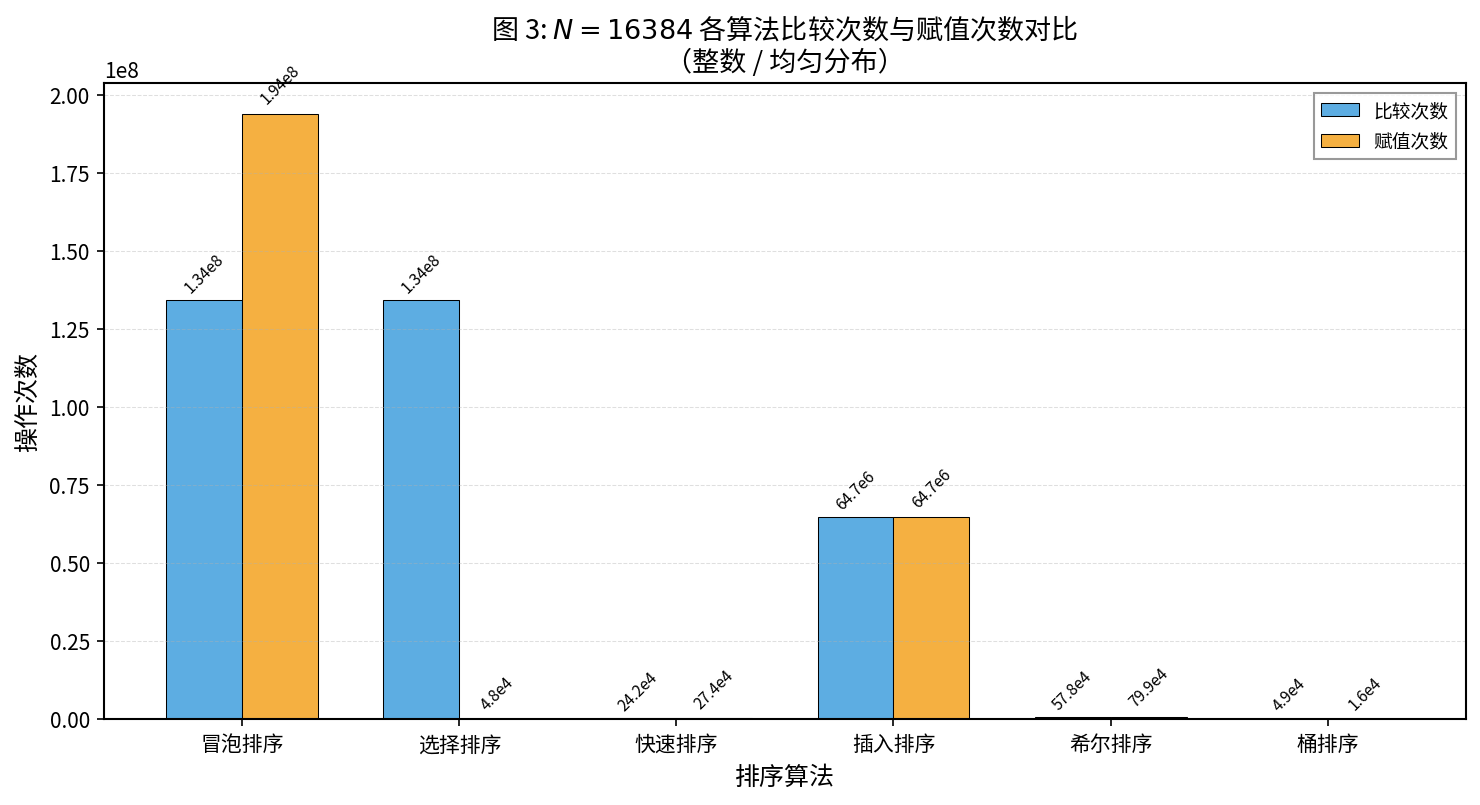

N=16384 整数均匀分布数据:
  算法   执行时间_s        比较次数        赋值次数
冒泡排序 0.585073 134209536.0 194094312.0
选择排序 0.180823 134209536.0     47814.0
快速排序 0.001025    242427.0    273756.0
插入排序 0.158459  64714485.0  64730870.0
希尔排序 0.002791    578227.0    798802.0
 桶排序 0.000616     49149.0     16384.0


In [6]:
# ========== 图表 3: N=16384 分组柱状图 ==========
mask_3 = (df['数据类型'] == 'i') & (df['数据构型'] == '均匀分布') & (df['规模N'] == 16384)
df_3 = df[mask_3].dropna(subset=['比较次数', '赋值次数']).copy()

fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(len(ALGO_NAMES))
width = 0.35

cmp_vals = [df_3[df_3['算法'] == a]['比较次数'].values[0] for a in ALGO_NAMES]
asg_vals = [df_3[df_3['算法'] == a]['赋值次数'].values[0] for a in ALGO_NAMES]

bars1 = ax.bar(x - width/2, cmp_vals, width, label='比较次数',
               color='#5DADE2', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, asg_vals, width, label='赋值次数',
               color='#F5B041', edgecolor='black', linewidth=0.5)

# 在柱子上方标注数值（科学计数法简化，仅对较大值标注）
def format_val(v):
    if v >= 1e8:
        return f'{v/1e8:.2f}e8'
    elif v >= 1e6:
        return f'{v/1e6:.1f}e6'
    elif v >= 1e4:
        return f'{v/1e4:.1f}e4'
    else:
        return f'{v:.0f}'

for bar, val in zip(bars1, cmp_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(cmp_vals)*0.01,
            format_val(val), ha='center', va='bottom', fontsize=7.5, rotation=45)
for bar, val in zip(bars2, asg_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(asg_vals)*0.01,
            format_val(val), ha='center', va='bottom', fontsize=7.5, rotation=45)

ax.set_xlabel('排序算法')
ax.set_ylabel('操作次数')
ax.set_title('图 3: $N=16384$ 各算法比较次数与赋值次数对比\n（整数 / 均匀分布）')
ax.set_xticks(x)
ax.set_xticklabels(ALGO_NAMES)
ax.legend(frameon=True, fancybox=False, edgecolor='gray')
ax.grid(True, axis='y', linestyle='--', alpha=0.4, linewidth=0.5)

plt.tight_layout()
plt.savefig('fig3_grouped_bar_n16384.png', dpi=300)
plt.show()

# 打印具体数值供参考
print('N=16384 整数均匀分布数据:')
print(df_3[['算法', '执行时间_s', '比较次数', '赋值次数']].to_string(index=False))

---
## 第三组：特殊构型数据的表现
### 图表 4：特殊构型对插入排序与冒泡排序的影响（分组柱状图）

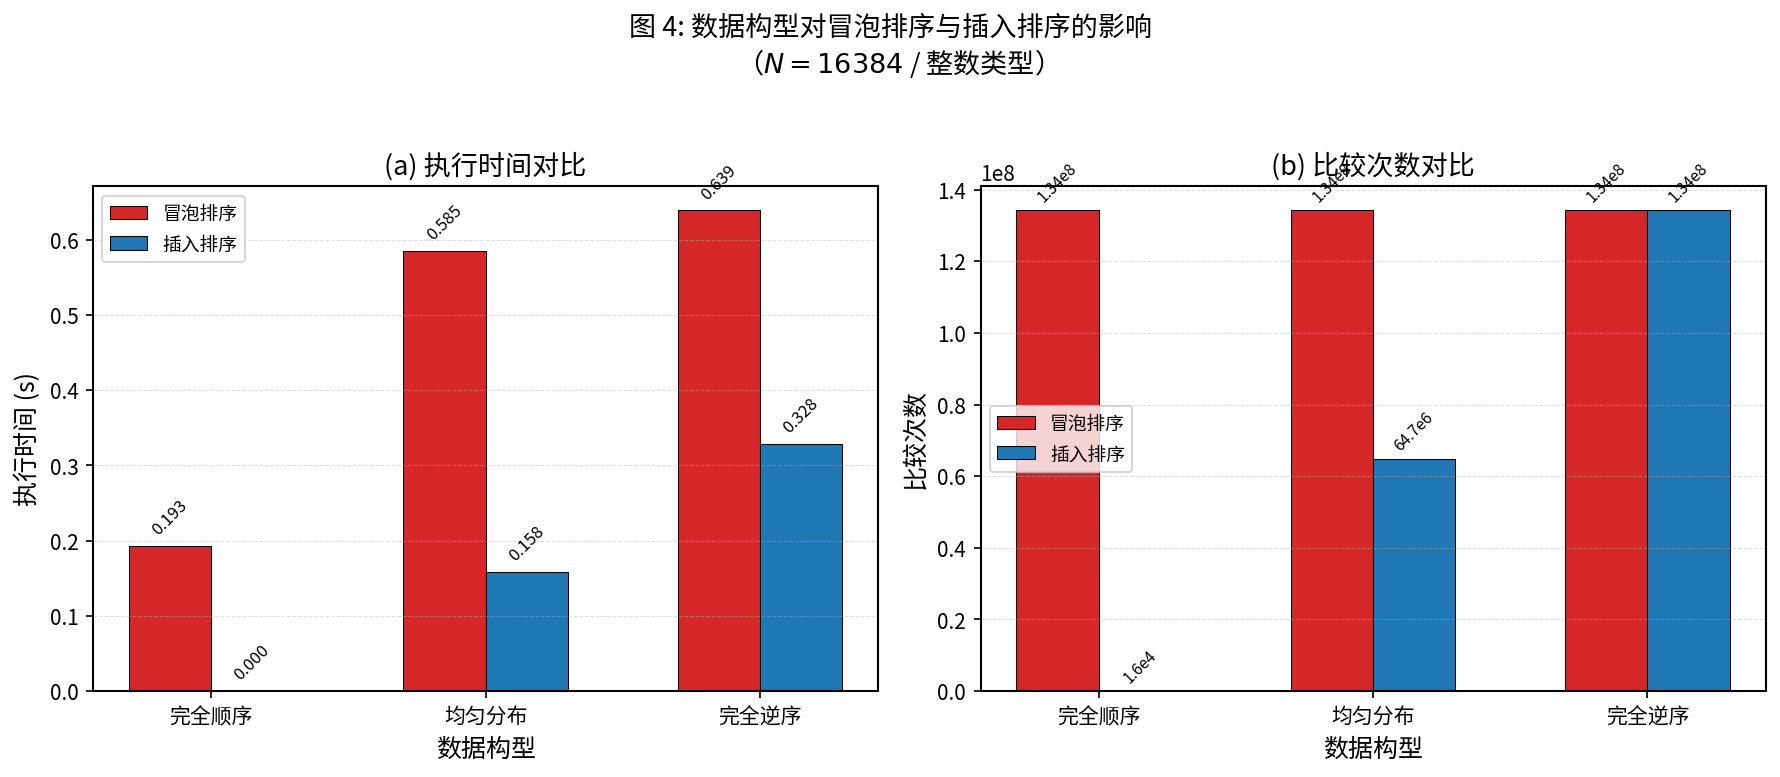

In [7]:
# ========== 图表 4: 特殊构型对比（冒泡 vs 插入） ==========
mask_4 = (df['数据类型'] == 'i') & (df['规模N'] == 16384) & \
         (df['数据构型'].isin(['完全顺序', '完全逆序', '均匀分布'])) & \
         (df['算法'].isin(['冒泡排序', '插入排序']))
df_4 = df[mask_4].dropna(subset=['执行时间_s']).copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

configs = ['完全顺序', '均匀分布', '完全逆序']
colors_4 = {'冒泡排序': '#d62728', '插入排序': '#1f77b4'}

# 图4-a: 执行时间
ax = axes[0]
x = np.arange(len(configs))
width = 0.3
for i, algo in enumerate(['冒泡排序', '插入排序']):
    vals = []
    for cfg in configs:
        row = df_4[(df_4['算法'] == algo) & (df_4['数据构型'] == cfg)]
        vals.append(row['执行时间_s'].values[0] if len(row) else 0)
    bars = ax.bar(x + (i - 0.5) * width, vals, width, label=algo,
                  color=colors_4[algo], edgecolor='black', linewidth=0.5)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8, rotation=45)
ax.set_xlabel('数据构型')
ax.set_ylabel('执行时间 (s)')
ax.set_title('(a) 执行时间对比')
ax.set_xticks(x)
ax.set_xticklabels(configs)
ax.legend()
ax.grid(True, axis='y', linestyle='--', alpha=0.4, linewidth=0.5)

# 图4-b: 比较次数
ax = axes[1]
for i, algo in enumerate(['冒泡排序', '插入排序']):
    vals = []
    for cfg in configs:
        row = df_4[(df_4['算法'] == algo) & (df_4['数据构型'] == cfg)]
        vals.append(row['比较次数'].values[0] if len(row) else 0)
    bars = ax.bar(x + (i - 0.5) * width, vals, width, label=algo,
                  color=colors_4[algo], edgecolor='black', linewidth=0.5)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.01,
                format_val(val), ha='center', va='bottom', fontsize=7.5, rotation=45)
ax.set_xlabel('数据构型')
ax.set_ylabel('比较次数')
ax.set_title('(b) 比较次数对比')
ax.set_xticks(x)
ax.set_xticklabels(configs)
ax.legend()
ax.grid(True, axis='y', linestyle='--', alpha=0.4, linewidth=0.5)

fig.suptitle('图 4: 数据构型对冒泡排序与插入排序的影响\n（$N=16384$ / 整数类型）', fontsize=13, y=1.03)
plt.tight_layout()
plt.savefig('fig4_config_impact.png', dpi=300)
plt.show()

### 图表 5：各算法对极端数据的鲁棒性（热力图）

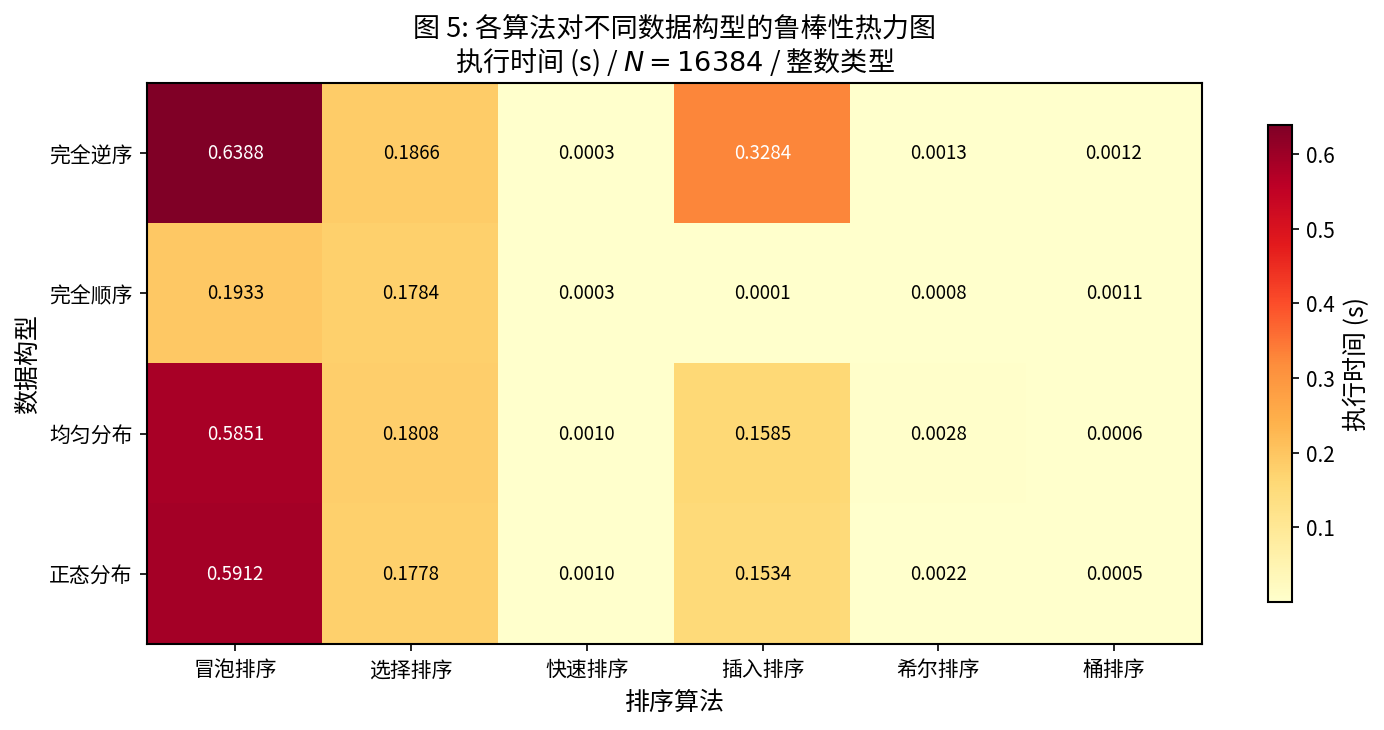

In [8]:
# ========== 图表 5: 热力图 —— 各算法 × 各数据构型的执行时间 ==========
mask_5 = (df['数据类型'] == 'i') & (df['规模N'] == 16384)
df_5 = df[mask_5].dropna(subset=['执行时间_s']).copy()

configs_order = ['完全逆序', '完全顺序', '均匀分布', '正态分布']
algos_order = ALGO_NAMES

# 构建热力图矩阵
heatmap_data = np.zeros((len(configs_order), len(algos_order)))
annot_data = np.empty((len(configs_order), len(algos_order)), dtype=object)

for i, cfg in enumerate(configs_order):
    for j, algo in enumerate(algos_order):
        row = df_5[(df_5['数据构型'] == cfg) & (df_5['算法'] == algo)]
        if len(row):
            t = row['执行时间_s'].values[0]
            heatmap_data[i, j] = t
            annot_data[i, j] = f'{t:.4f}'
        else:
            heatmap_data[i, j] = np.nan
            annot_data[i, j] = 'N/A'

fig, ax = plt.subplots(figsize=(10, 5))

# 使用对数归一化以更好地区分颜色
vmin = np.nanmin(heatmap_data)
vmax = np.nanmax(heatmap_data)

im = ax.imshow(heatmap_data, cmap='YlOrRd', aspect='auto', vmin=vmin, vmax=vmax)

# 标注数值
for i in range(len(configs_order)):
    for j in range(len(algos_order)):
        val = heatmap_data[i, j]
        if not np.isnan(val):
            # 根据背景深浅选择文字颜色
            norm_val = (val - vmin) / (vmax - vmin) if vmax > vmin else 0
            text_color = 'white' if norm_val > 0.5 else 'black'
            ax.text(j, i, f'{val:.4f}', ha='center', va='center',
                    fontsize=9, fontweight='bold', color=text_color)

ax.set_xticks(range(len(algos_order)))
ax.set_xticklabels(algos_order)
ax.set_yticks(range(len(configs_order)))
ax.set_yticklabels(configs_order)
ax.set_xlabel('排序算法')
ax.set_ylabel('数据构型')
ax.set_title('图 5: 各算法对不同数据构型的鲁棒性热力图\n执行时间 (s) / $N=16384$ / 整数类型')

cbar = plt.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label('执行时间 (s)')

plt.tight_layout()
plt.savefig('fig5_heatmap_robustness.png', dpi=300)
plt.show()

---
## 补充表格：学术三线表
### 表格 1：$N=16384$ 时不同算法的基础数据对比（整数类型）

表 1: N=16384 时不同算法的基础数据对比表（整数类型）
  算法 完全顺序-耗时(s)   完全顺序-比较次数 完全顺序-赋值次数 均匀分布-耗时(s)   均匀分布-比较次数   均匀分布-赋值次数
冒泡排序     0.1933 134,209,536         0     0.5851 134,209,536 194,094,312
选择排序     0.1784 134,209,536         0     0.1808 134,209,536      47,814
快速排序     0.0003     213,008    32,768     0.0010     242,427     273,756
插入排序     0.0001      16,383    32,766     0.1585  64,714,485  64,730,870
希尔排序     0.0008     212,993   425,986     0.0028     578,227     798,802
 桶排序     0.0011      49,149    16,384     0.0006      49,149      16,384


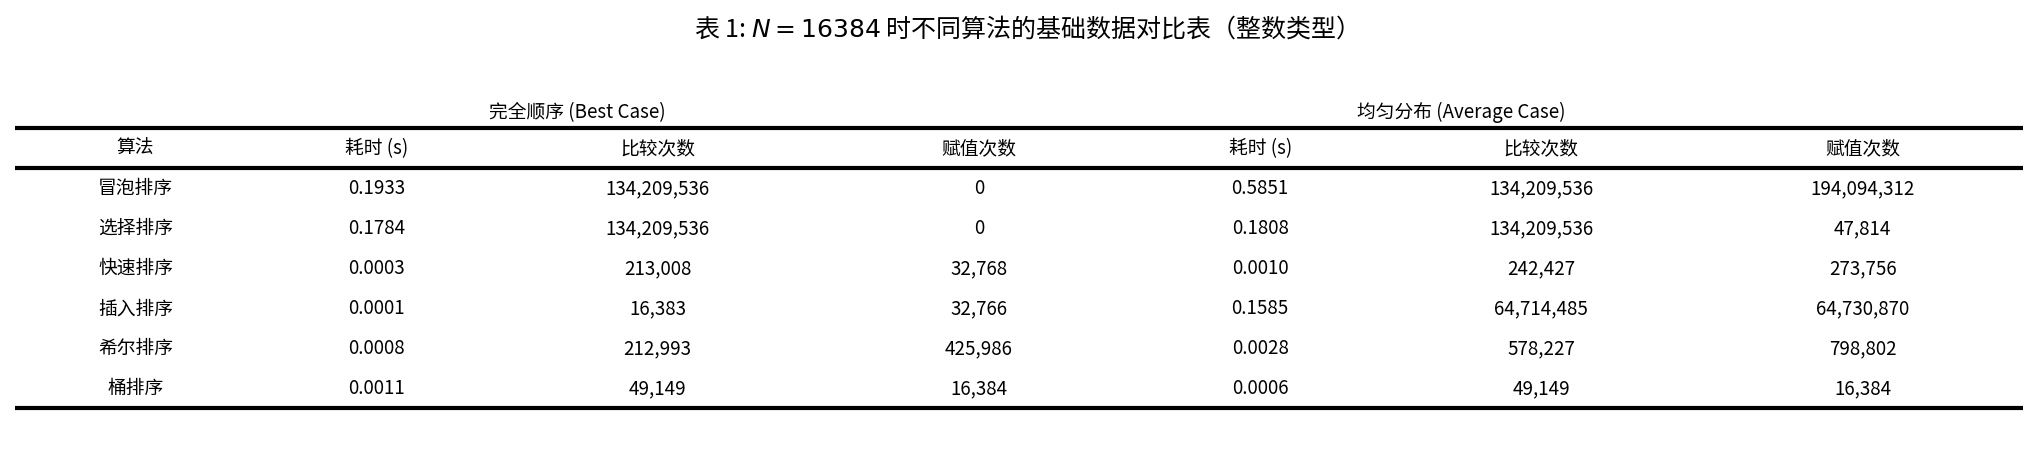

In [9]:
# ========== 表格 1: N=16384 学术三线表 ==========
mask_t1 = (df['数据类型'] == 'i') & (df['规模N'] == 16384) & \
          (df['数据构型'].isin(['完全顺序', '均匀分布']))
df_t1 = df[mask_t1].dropna(subset=['执行时间_s']).copy()

# 构建表格数据
table_data = []
for algo in ALGO_NAMES:
    row_complete = df_t1[(df_t1['算法'] == algo) & (df_t1['数据构型'] == '完全顺序')]
    row_uniform = df_t1[(df_t1['算法'] == algo) & (df_t1['数据构型'] == '均匀分布')]
    
    table_data.append({
        '算法': algo,
        '完全顺序-耗时(s)': f"{row_complete['执行时间_s'].values[0]:.4f}" if len(row_complete) else '-',
        '完全顺序-比较次数': f"{row_complete['比较次数'].values[0]:,.0f}" if len(row_complete) else '-',
        '完全顺序-赋值次数': f"{row_complete['赋值次数'].values[0]:,.0f}" if len(row_complete) else '-',
        '均匀分布-耗时(s)': f"{row_uniform['执行时间_s'].values[0]:.4f}" if len(row_uniform) else '-',
        '均匀分布-比较次数': f"{row_uniform['比较次数'].values[0]:,.0f}" if len(row_uniform) else '-',
        '均匀分布-赋值次数': f"{row_uniform['赋值次数'].values[0]:,.0f}" if len(row_uniform) else '-',
    })

df_table1 = pd.DataFrame(table_data)
print('表 1: N=16384 时不同算法的基础数据对比表（整数类型）')
print('=' * 100)
print(df_table1.to_string(index=False))

# ========== 绘制学术三线表（Matplotlib 原生 visible_edges 方案） ==========
col_labels = ['算法', '耗时 (s)', '比较次数', '赋值次数', '耗时 (s)', '比较次数', '赋值次数']
cell_text = []
for _, row in df_table1.iterrows():
    cell_text.append([row['算法'],
                      row['完全顺序-耗时(s)'], row['完全顺序-比较次数'], row['完全顺序-赋值次数'],
                      row['均匀分布-耗时(s)'], row['均匀分布-比较次数'], row['均匀分布-赋值次数']])

nrows = len(cell_text)   # 数据行数（不包含表头）
ncols = len(col_labels)

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.axis('off')

# 创建表格，默认无边框
col_widths = [0.12, 0.12, 0.16, 0.16, 0.12, 0.16, 0.16]
table = ax.table(
    cellText=cell_text,
    colLabels=col_labels,
    cellLoc='center',
    loc='center',
    colWidths=col_widths,
    edges='open',
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.0, 1.8)

# ===== 核心：通过 visible_edges 直接绘制三线表 =====
# 三线表规则：
#   - 表头行(row=0): 顶线(Top) + 底线(Bottom) → 'TB'
#   - 数据中间行: 无边框
#   - 最后数据行(row=nrows): 仅底线(Bottom) → 'B'
for (row, col), cell in table.get_celld().items():
    cell.set_facecolor('white')
    cell.set_edgecolor('black')

    if row == 0:                          # 表头
        cell.visible_edges = 'TB'
        cell.set_linewidth(2.0)
        cell.set_text_props(weight='bold', fontsize=9)
    elif row == nrows:                    # 最后一行数据
        cell.visible_edges = 'B'
        cell.set_linewidth(2.0)
    else:                                 # 中间数据行
        cell.visible_edges = ''
        cell.set_linewidth(0)

# 标题和分组标注
ax.set_title('表 1: $N=16384$ 时不同算法的基础数据对比表（整数类型）',
             fontsize=12, fontweight='bold', pad=25, loc='center')
ax.text(0.28, 0.92, '完全顺序 (Best Case)', transform=ax.transAxes,
        fontsize=9, ha='center', fontstyle='italic')
ax.text(0.72, 0.92, '均匀分布 (Average Case)', transform=ax.transAxes,
        fontsize=9, ha='center', fontstyle='italic')

plt.tight_layout(pad=2.0)
plt.savefig('table1_academic_three_line.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()

---
## 附：组合图 —— 综合展示（可选）
### 图表 1-a 与 1-b 的组合展示

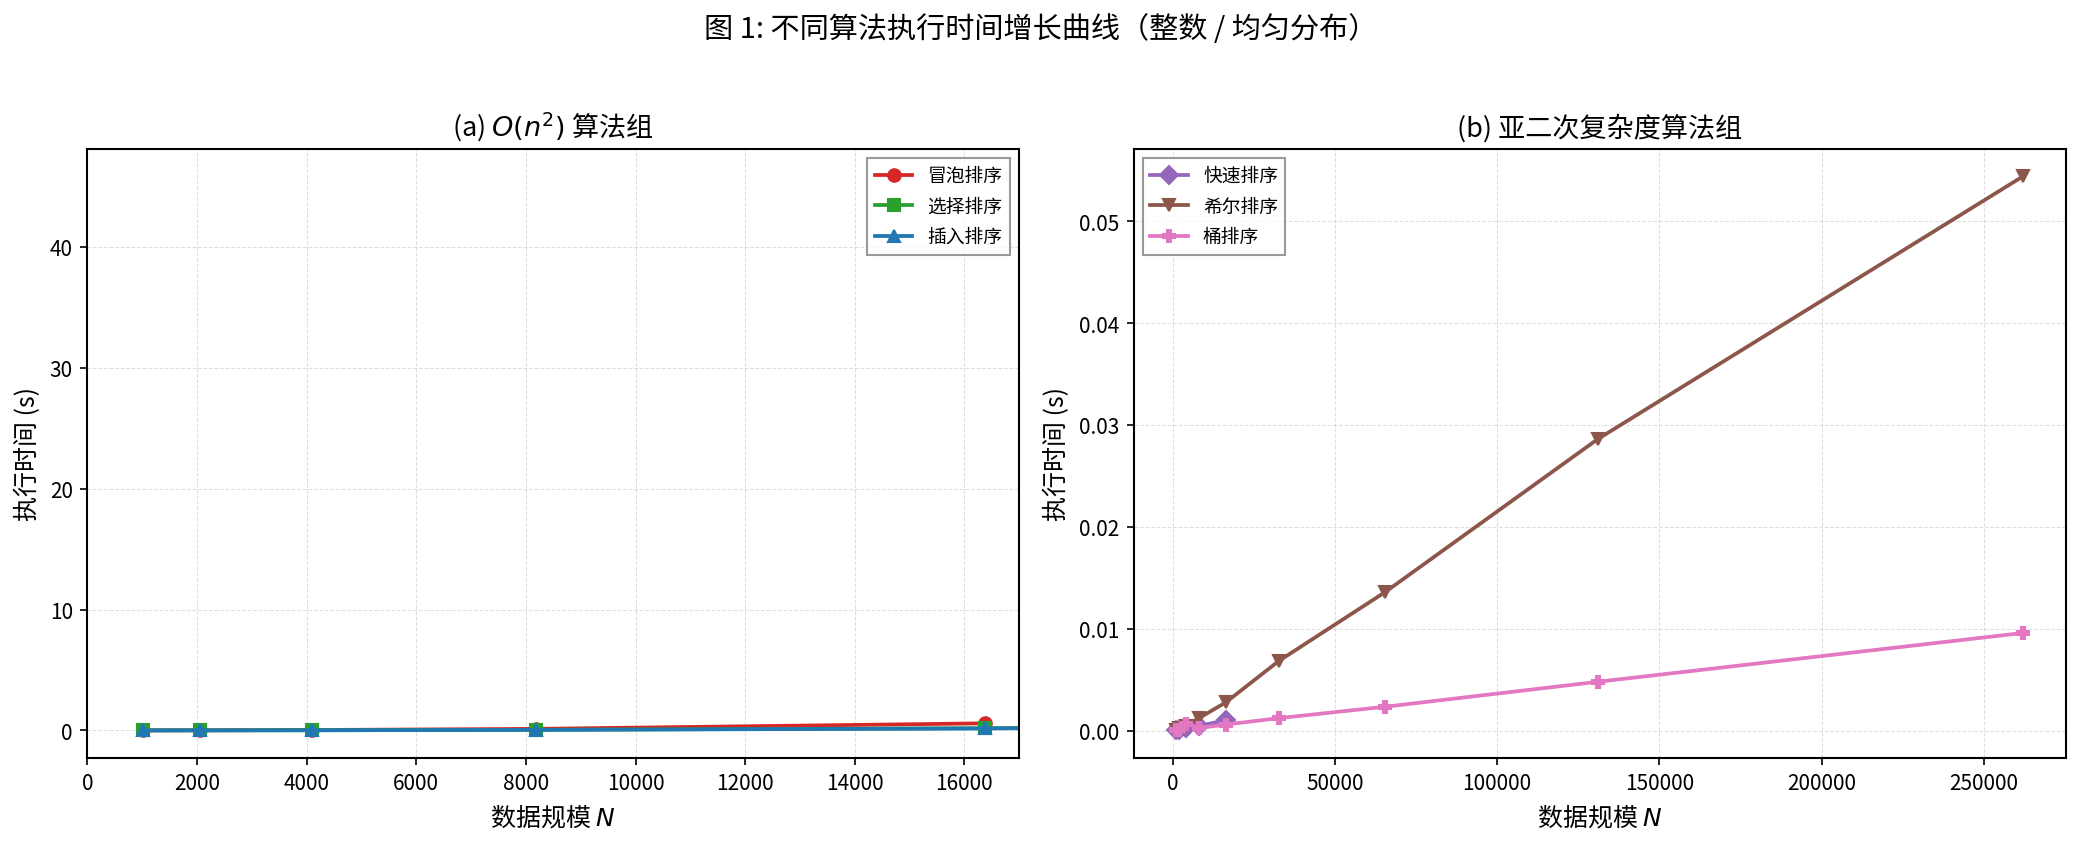

In [10]:
# ========== 组合图：图表1-a + 1-b ==========
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 左图: O(n^2)
ax = axes[0]
for algo in ['冒泡排序', '选择排序', '插入排序']:
    sub = df_1a[df_1a['算法'] == algo].sort_values('规模N')
    ax.plot(sub['规模N'], sub['执行时间_s'],
            color=colors_o2[algo], marker=markers_o2[algo],
            linewidth=1.8, markersize=6, label=algo)
ax.set_xlabel('数据规模 $N$')
ax.set_ylabel('执行时间 (s)')
ax.set_title('(a) $O(n^2)$ 算法组')
ax.legend(frameon=True, fancybox=False, edgecolor='gray')
ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.5)
ax.set_xlim(0, 17000)

# 右图: 快速算法
ax = axes[1]
for algo in ['快速排序', '希尔排序', '桶排序']:
    sub = df_1b[df_1b['算法'] == algo].sort_values('规模N')
    ax.plot(sub['规模N'], sub['执行时间_s'],
            color=colors_fast[algo], marker=markers_fast[algo],
            linewidth=1.8, markersize=6, label=algo)
ax.set_xlabel('数据规模 $N$')
ax.set_ylabel('执行时间 (s)')
ax.set_title('(b) 亚二次复杂度算法组')
ax.legend(frameon=True, fancybox=False, edgecolor='gray')
ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.5)

fig.suptitle('图 1: 不同算法执行时间增长曲线（整数 / 均匀分布）', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('fig1_combined_time_curves.png', dpi=300)
plt.show()

---
## 补充：双精度浮点数的性能对比（可选）

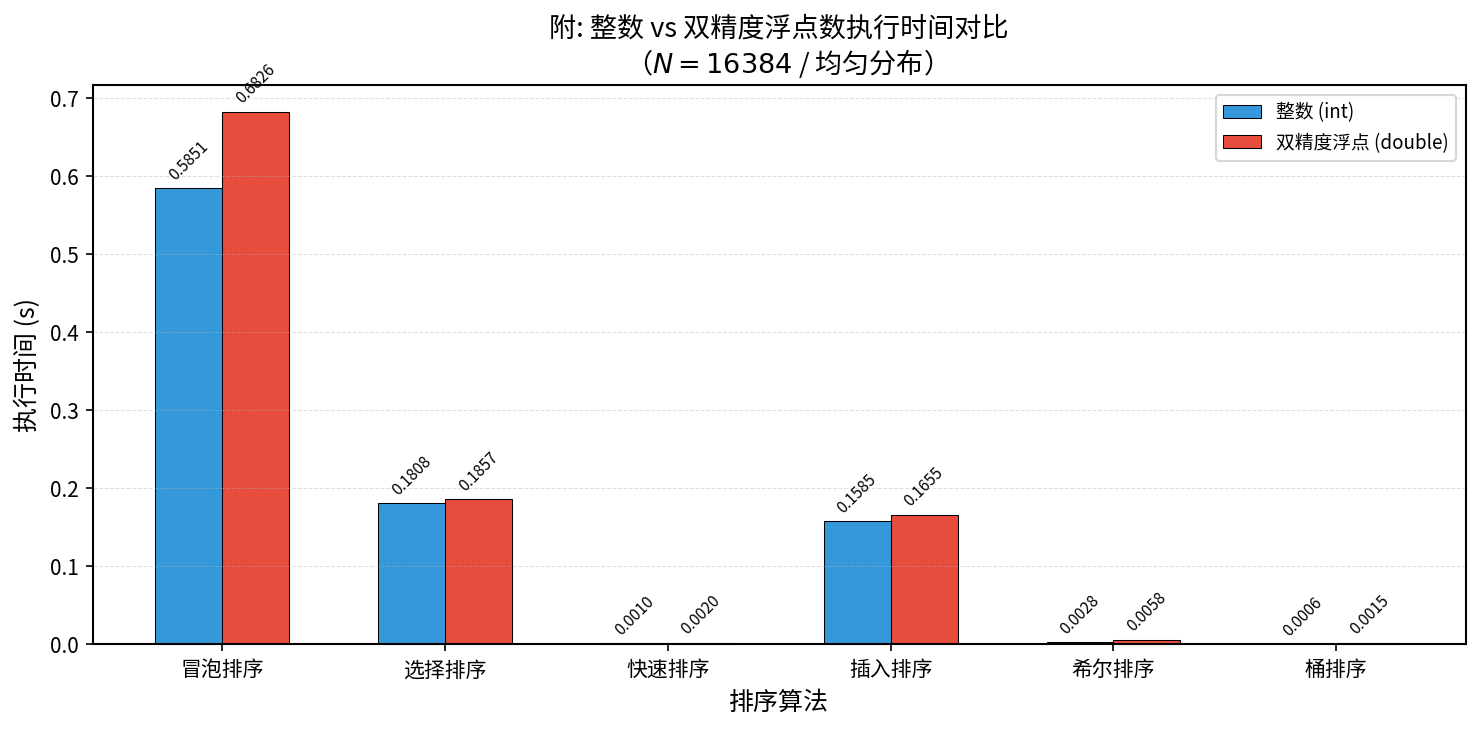

In [11]:
# ========== 补充: 整数 vs 双精度浮点 时间对比（均匀分布 N=16384） ==========
mask_extra = (df['数据构型'] == '均匀分布') & (df['规模N'] == 16384)
df_extra = df[mask_extra].dropna(subset=['执行时间_s']).copy()

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(ALGO_NAMES))
width = 0.3

for i, (dtype_label, color) in enumerate(zip(['i', 'd'], ['#3498DB', '#E74C3C'])):
    vals = []
    for algo in ALGO_NAMES:
        row = df_extra[(df_extra['数据类型'] == dtype_label) & (df_extra['算法'] == algo)]
        vals.append(row['执行时间_s'].values[0] if len(row) else 0)
    label = '整数 (int)' if dtype_label == 'i' else '双精度浮点 (double)'
    bars = ax.bar(x + (i - 0.5) * width, vals, width, label=label,
                  color=color, edgecolor='black', linewidth=0.5)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.01,
                f'{val:.4f}', ha='center', va='bottom', fontsize=7.5, rotation=45)

ax.set_xlabel('排序算法')
ax.set_ylabel('执行时间 (s)')
ax.set_title('附: 整数 vs 双精度浮点数执行时间对比\n（$N=16384$ / 均匀分布）')
ax.set_xticks(x)
ax.set_xticklabels(ALGO_NAMES)
ax.legend()
ax.grid(True, axis='y', linestyle='--', alpha=0.4, linewidth=0.5)

plt.tight_layout()
plt.savefig('fig_extra_int_vs_double.png', dpi=300)
plt.show()

In [12]:
print('=' * 60)
print('所有图表已生成完毕！')
print('输出文件列表:')
import os
for f in sorted(os.listdir('.')):
    if f.endswith('.png'):
        size_kb = os.path.getsize(f) / 1024
        print(f'  ✓ {f} ({size_kb:.1f} KB)')
print('=' * 60)

所有图表已生成完毕！
输出文件列表:
  ✓ fig1_combined_time_curves.png (266.1 KB)
  ✓ fig1a_o_n2_time_curve.png (131.5 KB)
  ✓ fig1b_fast_time_curve.png (182.7 KB)
  ✓ fig2_operations_log_scale.png (439.1 KB)
  ✓ fig3_grouped_bar_n16384.png (203.4 KB)
  ✓ fig4_config_impact.png (247.5 KB)
  ✓ fig5_heatmap_robustness.png (214.5 KB)
  ✓ fig_extra_int_vs_double.png (197.5 KB)
  ✓ table1_academic_three_line.png (203.1 KB)
